In [ ]:
import zipfile
import os

zip_path = "/content/food11.zip"
extract_path = "/content/food11"

print("ZIP file exists:", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("ZIP extraction completed!")
print(os.listdir(extract_path))


ZIP file exists: True
ZIP extraction completed!
['food11']


In [ ]:
import os

# Find train and test folder automatically
for root, dirs, files in os.walk("/content/food11"):
    if "train" in dirs:
        train_path = os.path.join(root, "train")
        test_path = os.path.join(root, "test")
        break

print("Train path:", train_path)
print("Test path:", test_path)

classes = sorted(os.listdir(train_path))

print("Total food categories:", len(classes))
print(classes)

for category in classes:
    folder = os.path.join(train_path, category)
    print(category, ":", len(os.listdir(folder)), "files")

Train path: /content/food11/food11/train
Test path: /content/food11/food11/test
Total food categories: 11
['apple_pie', 'cheesecake', 'chicken_curry', 'french_fries', 'fried_rice', 'hamburger', 'hot_dog', 'ice_cream', 'omelette', 'pizza', 'sushi']
apple_pie : 900 files
cheesecake : 900 files
chicken_curry : 900 files
french_fries : 900 files
fried_rice : 900 files
hamburger : 900 files
hot_dog : 900 files
ice_cream : 900 files
omelette : 900 files
pizza : 900 files
sushi : 900 files


Image name: 2546216.jpg
Image size: (512, 512)
Image mode: RGB


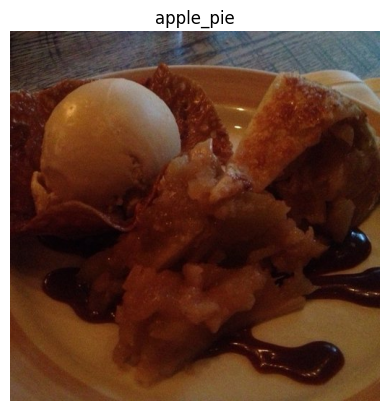

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

folder = os.path.join(train_path, classes[0])
image_name = os.listdir(folder)[0]
image_path = os.path.join(folder, image_name)

img = Image.open(image_path)

print("Image name:", image_name)
print("Image size:", img.size)
print("Image mode:", img.mode)

plt.imshow(img)
plt.title(classes[0])
plt.axis("off")
plt.show()

In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available devices:", tf.config.list_physical_devices())

TensorFlow version: 2.21.0
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [ ]:
# Import Libraries
import tensorflow as tf
import os

# Load Training Data (80%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=(128, 128),
    batch_size=32
)

# Load Validation Data (20%)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(128, 128),
    batch_size=32
)

# Load Testing Data
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(128, 128),
    batch_size=32,
    shuffle=False
)

# Check Number of Classes
print("Classes:", train_ds.class_names)
print("Total Classes:", len(train_ds.class_names))

Found 9900 files belonging to 11 classes.
Using 7920 files for training.
Found 9900 files belonging to 11 classes.
Using 1980 files for validation.
Found 1100 files belonging to 11 classes.
Classes: ['apple_pie', 'cheesecake', 'chicken_curry', 'french_fries', 'fried_rice', 'hamburger', 'hot_dog', 'ice_cream', 'omelette', 'pizza', 'sushi']
Total Classes: 11


In [ ]:
# Create Model
from tensorflow.keras.models import Sequential

model = Sequential()

# Import CNN Layers
from tensorflow.keras.layers import (
    Input, Rescaling, Conv2D, MaxPool2D,
    Flatten, Dense, Dropout,
    RandomFlip, RandomRotation, RandomZoom
)

# Define Input Layer
model.add(Input(shape=(128, 128, 3)))

# Data Augmentation
model.add(RandomFlip("horizontal"))
model.add(RandomRotation(0.1))
model.add(RandomZoom(0.1))

# Normalize Pixel Values (0-255 to 0-1)
model.add(Rescaling(1./255))

# First Convolutional Layer
model.add(Conv2D(32, (3, 3), activation="relu"))

# First Max Pooling Layer
model.add(MaxPool2D((2, 2)))

# Second Convolutional Layer
model.add(Conv2D(64, (3, 3), activation="relu"))

# Second Max Pooling Layer
model.add(MaxPool2D((2, 2)))

# Third Convolutional Layer
model.add(Conv2D(128, (3, 3), activation="relu"))

# Third Max Pooling Layer
model.add(MaxPool2D((2, 2)))

# Flatten Layer
model.add(Flatten())

# Fully Connected Layer
model.add(Dense(128, activation="relu"))

# Dropout Layer
model.add(Dropout(0.5))

# Output Layer (11 Food Classes)
model.add(Dense(len(train_ds.class_names), activation="softmax"))

# Display Model Architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,059 (12.61 MB)

 Trainable params: 3,306,059 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile Model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [ ]:
# Train Model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 302s 1s/step - accuracy: 0.1314 - loss: 2.3620 - val_accuracy: 0.1924 - val_loss: 2.2481
Epoch 2/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 306s 1s/step - accuracy: 0.1948 - loss: 2.2603 - val_accuracy: 0.2333 - val_loss: 2.1679
Epoch 3/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 297s 1s/step - accuracy: 0.2206 - loss: 2.2058 - val_accuracy: 0.2601 - val_loss: 2.1253
Epoch 4/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 290s 1s/step - accuracy: 0.2426 - loss: 2.1680 - val_accuracy: 0.2843 - val_loss: 2.0793
Epoch 5/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 298s 1s/step - accuracy: 0.2535 - loss: 2.1323 - val_accuracy: 0.3040 - val_loss: 2.0312


In [13]:
# Continue Training (same model, 10 more epochs)
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 294s 1s/step - accuracy: 0.3194 - loss: 1.9941 - val_accuracy: 0.3449 - val_loss: 1.9153
Epoch 2/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 296s 1s/step - accuracy: 0.3376 - loss: 1.9467 - val_accuracy: 0.3611 - val_loss: 1.9042
Epoch 3/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 320s 1s/step - accuracy: 0.3451 - loss: 1.9199 - val_accuracy: 0.3657 - val_loss: 1.9081
Epoch 4/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 297s 1s/step - accuracy: 0.3562 - loss: 1.8893 - val_accuracy: 0.3949 - val_loss: 1.8339
Epoch 5/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 295s 1s/step - accuracy: 0.3715 - loss: 1.8487 - val_accuracy: 0.3712 - val_loss: 1.8573
Epoch 6/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 322s 1s/step - accuracy: 0.3809 - loss: 1.8299 - val_accuracy: 0.3955 - val_loss: 1.8625
Epoch 7/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 293s 1s/step - accuracy: 0.3928 - loss: 1.7970 - val_accuracy: 0.3859 - val_loss: 1.8455
Epoch 8/10
248/248 ━━━━━━━━━━━━━━━━━━━━ 295s 1s/step - accuracy: 0.3961 - loss: 1.7751 - val_accu

In [14]:
# Evaluate Model on Test Data
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

35/35 ━━━━━━━━━━━━━━━━━━━━ 10s 274ms/step - accuracy: 0.4036 - loss: 1.8133
Test Loss: 1.8132541179656982
Test Accuracy: 40.36363661289215 %


In [15]:
# Save Model and Download to Laptop
from google.colab import files

model.save("/content/food11_cnn.keras")
files.download("/content/food11_cnn.keras")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
# Classification Report
import numpy as np
from sklearn.metrics import classification_report

y_actual = np.concatenate([y.numpy() for x, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(
    y_actual,
    y_pred,
    target_names=test_ds.class_names,
    zero_division=0
))

35/35 ━━━━━━━━━━━━━━━━━━━━ 11s 306ms/step
               precision    recall  f1-score   support

    apple_pie       0.27      0.21      0.24       100
   cheesecake       0.39      0.67      0.49       100
chicken_curry       0.43      0.44      0.43       100
 french_fries       0.74      0.37      0.49       100
   fried_rice       0.46      0.46      0.46       100
    hamburger       0.34      0.38      0.36       100
      hot_dog       0.48      0.16      0.24       100
    ice_cream       0.45      0.44      0.44       100
     omelette       0.67      0.24      0.35       100
        pizza       0.32      0.69      0.44       100
        sushi       0.38      0.38      0.38       100

     accuracy                           0.40      1100
    macro avg       0.45      0.40      0.39      1100
 weighted avg       0.45      0.40      0.39      1100



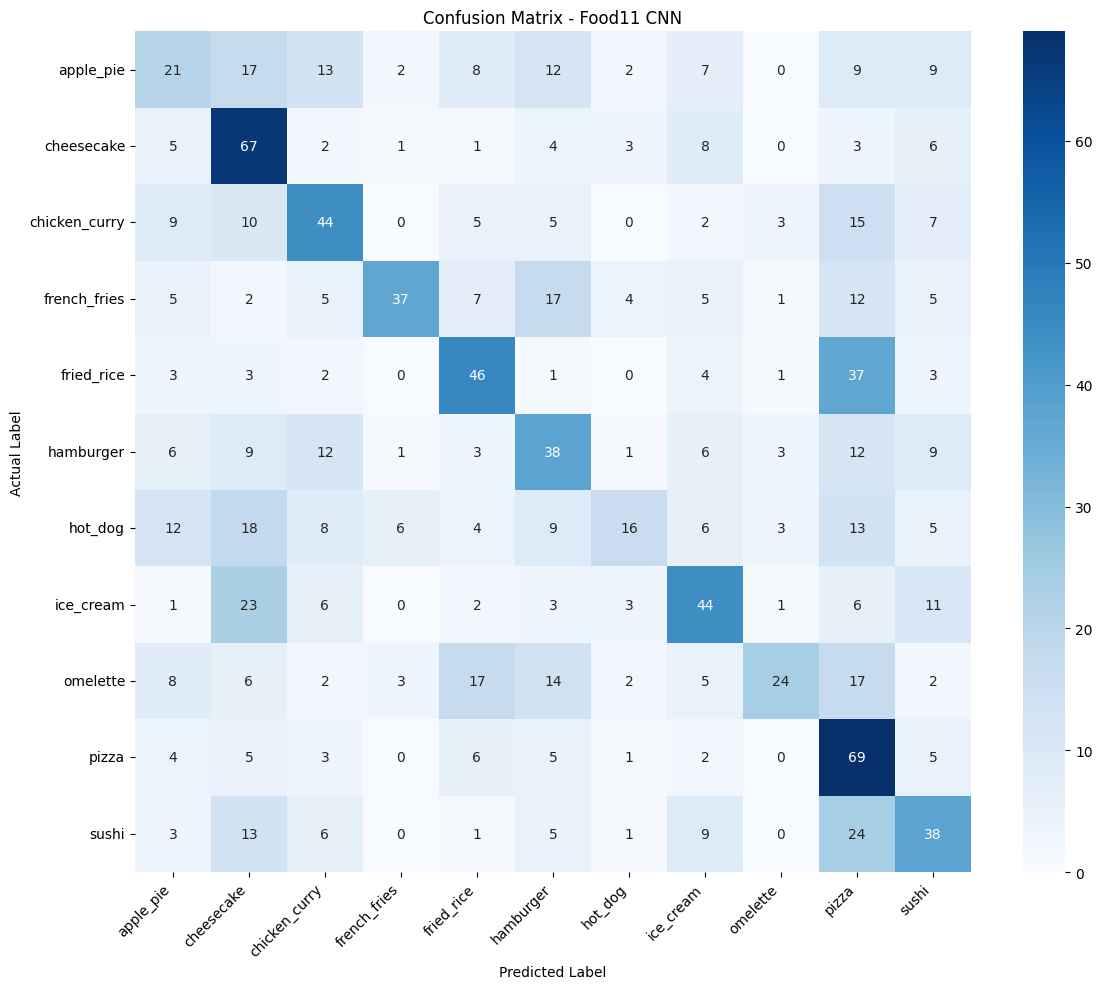

In [17]:
# Confusion Matrix
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_actual, y_pred)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_ds.class_names,
    yticklabels=test_ds.class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Food11 CNN")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
# Predict One Test Image
for images, labels in test_ds.take(1):
    predictions = model.predict(images)
    predicted_class = np.argmax(predictions[0])
    actual_class = test_ds.class_names[labels[0].numpy()]

    print("Predicted Food:", test_ds.class_names[predicted_class])
    print("Actual Food:", actual_class)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Predicted Food: cheesecake
Actual Food: apple_pie
